In [1]:
!pip install lpips

In [2]:
# ==============================
# DLG + iDLG + GradInversion
# REAL FL CLIENT UPDATE VERSION
# FMNIST (10 classes)
# 4 Models:
# Baseline
# Masking Only
# Masking + ANF=0.1
# Masking + ANF=0.2
# ==============================

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import numpy as np
import random
import copy
import os
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr
from sklearn.metrics import mean_squared_error
import lpips

# -------------------------
# Seed
# -------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# -------------------------
# Device
# -------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# -------------------------
# LPIPS
# -------------------------
lpips_fn = lpips.LPIPS(net='squeeze').to(DEVICE)

# -------------------------
# Dataset
# -------------------------
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

NUM_CLASSES = 10

# -------------------------
# Model
# -------------------------
class FMNIST_CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(64 * 7 * 7, 256)
        self.fc2 = nn.Linear(256, NUM_CLASSES)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

# -------------------------
# Load models
# -------------------------
def load_model(path):
    m = FMNIST_CNN().to(DEVICE)
    m.load_state_dict(torch.load(path, map_location=DEVICE))
    m.eval()
    return m

models = {
    "baseline": load_model("Baseline_fmnist.pth"),
    "fpman0": load_model("FPMAN_fmnist_0.pth"),
    "fpman1": load_model("FPMAN_fmnist_1.pth"),
    "fpman2": load_model("FPMAN_fmnist_2.pth")
}

# -------------------------
# One sample per class (FIXED like Code 1)
# -------------------------
letter_samples = {}
counts = {i: 0 for i in range(10)}

for img, label in dataset:
    if counts[label] == 0:
        letter_samples[label] = img
        counts[label] += 1

    if all(v > 0 for v in counts.values()):
        break

# -------------------------
# FL CLIENT UPDATE
# -------------------------
def get_client_update(model, image, label):

    local = copy.deepcopy(model)
    local.train()

    opt = torch.optim.SGD(local.parameters(), lr=0.01)

    for _ in range(5):
        opt.zero_grad()
        out = local(image)
        loss = F.cross_entropy(out, label)
        loss.backward()
        opt.step()

    delta = []
    for p0, p1 in zip(model.parameters(), local.parameters()):
        delta.append((p1.data - p0.data).clone().view(-1))

    return torch.cat(delta)

# -------------------------
# DLG
# -------------------------
def dlg_attack(model, update, shape, label, steps=300, lr=0.05):

    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    dummy = torch.randn(shape, device=DEVICE, requires_grad=True)
    opt = torch.optim.Adam([dummy], lr=lr)

    for _ in range(steps):
        opt.zero_grad()

        loss = F.cross_entropy(model(dummy), label)

        grads = torch.autograd.grad(loss, model.parameters(), create_graph=True)
        grad_vec = torch.cat([g.view(-1) for g in grads])

        loss = ((grad_vec - update) ** 2).sum()

        loss.backward()
        opt.step()

        dummy.data.clamp_(-1, 1)

    return dummy.detach()

# -------------------------
# iDLG (FIXED – real label recovery)
# -------------------------
def idlg_attack(model, update, shape, steps=300, lr=0.05):

    last_bias_size = model.fc2.bias.numel()
    bias_grad = update[-last_bias_size:]

    recovered_label = torch.argmin(bias_grad).view(1).to(DEVICE)
    print("Recovered Label:", recovered_label.item())

    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    dummy = torch.randn(shape, device=DEVICE, requires_grad=True)
    opt = torch.optim.Adam([dummy], lr=lr)

    for _ in range(steps):

        opt.zero_grad()

        pred = model(dummy)
        ce_loss = F.cross_entropy(pred, recovered_label)

        grads = torch.autograd.grad(ce_loss, model.parameters(), create_graph=True)
        grad_vec = torch.cat([g.view(-1) for g in grads])

        loss = ((grad_vec - update) ** 2).sum()

        loss.backward()
        opt.step()

        dummy.data.clamp_(-1, 1)

    return dummy.detach()

# -------------------------
# GradInv
# -------------------------
def gradinv_attack(model, update, shape, label, steps=300, lr=0.05):

    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    dummy = torch.randn(shape, device=DEVICE, requires_grad=True)
    opt = torch.optim.Adam([dummy], lr=lr)

    for _ in range(steps):

        opt.zero_grad()

        pred = model(dummy)

        ce_loss = F.cross_entropy(pred, label)

        grads = torch.autograd.grad(
            ce_loss,
            model.parameters(),
            create_graph=True
        )

        grad_vec = torch.cat([g.view(-1) for g in grads])

        grad_loss = ((grad_vec - update) ** 2).sum()

        tv_loss = (
            torch.mean(torch.abs(dummy[:, :, :, :-1] - dummy[:, :, :, 1:])) +
            torch.mean(torch.abs(dummy[:, :, :-1, :] - dummy[:, :, 1:, :]))
        )

        loss = grad_loss + 1e-2 * tv_loss

        loss.backward()
        opt.step()

        dummy.data.clamp_(-1, 1)

    return dummy.detach()

# -------------------------
# Metrics
# -------------------------
def compute_metrics(original, reconstructed):

    # -------------------------
    # normalize to [0,1]
    # -------------------------
    orig = original.copy()
    recon = reconstructed.copy()

    orig = (orig - orig.min()) / (orig.max() - orig.min() + 1e-8)
    recon = (recon - recon.min()) / (recon.max() - recon.min() + 1e-8)

    # -------------------------
    # MSE
    # -------------------------
    mse_value = mean_squared_error(
        orig.flatten(),
        recon.flatten()
    )

    # -------------------------
    # PSNR
    # -------------------------
    psnr_value = psnr(orig, recon, data_range=1.0)

    # -------------------------
    # SSIM
    # -------------------------
    ssim_value = ssim(orig, recon, data_range=1.0)

    # -------------------------
    # LPIPS
    # LPIPS expects:
    # tensor shape = [B,3,H,W]
    # range = [-1,1]
    # -------------------------

    orig_t = torch.tensor(orig).float().unsqueeze(0).unsqueeze(0)
    recon_t = torch.tensor(recon).float().unsqueeze(0).unsqueeze(0)

    # grayscale -> 3 channel
    orig_t = orig_t.repeat(1, 3, 1, 1)
    recon_t = recon_t.repeat(1, 3, 1, 1)

    # [0,1] -> [-1,1]
    orig_t = orig_t * 2 - 1
    recon_t = recon_t * 2 - 1

    orig_t = orig_t.to(DEVICE)
    recon_t = recon_t.to(DEVICE)

    lpips_value = lpips_fn(orig_t, recon_t).item()

    # -------------------------
    # Reconstruction Success Rate
    # success if SSIM >= 0.5
    # -------------------------
    success = 1 if (ssim_value >= 0.1 or psnr_value >= 10) else 0

    return mse_value, psnr_value, ssim_value, lpips_value, success

# -------------------------
# RUN ATTACKS
# -------------------------
results = {k: {"dlg": [], "idlg": [], "gi": []} for k in models}
original = []

metrics = {
    k: {
        "dlg": {
            "mse": [],
            "psnr": [],
            "ssim": [],
            "lpips": [],
            "success": []
        },
        "idlg": {
            "mse": [],
            "psnr": [],
            "ssim": [],
            "lpips": [],
            "success": []
        },
        "gi": {
            "mse": [],
            "psnr": [],
            "ssim": [],
            "lpips": [],
            "success": []
        },
    }
    for k in models
}

for c in range(10):

    print("\nClass:", c)

    img = letter_samples[c].unsqueeze(0).to(DEVICE)
    label = torch.tensor([c]).to(DEVICE)

    original.append(img.cpu().numpy()[0][0])

    for name, model in models.items():

        print("Model:", name)

        update = get_client_update(model, img, label)

        print(" DLG")
        r1 = dlg_attack(model, update, img.shape, label)
        recon1 = r1.cpu().numpy()[0][0]
        results[name]["dlg"].append(recon1)

        mse_v, psnr_v, ssim_v, lpips_v, success_v = compute_metrics(
            img.cpu().numpy()[0][0],
            recon1
        )

        metrics[name]["dlg"]["mse"].append(mse_v)
        metrics[name]["dlg"]["psnr"].append(psnr_v)
        metrics[name]["dlg"]["ssim"].append(ssim_v)
        metrics[name]["dlg"]["lpips"].append(lpips_v)
        metrics[name]["dlg"]["success"].append(success_v)

        print(" iDLG")
        r2 = idlg_attack(model, update, img.shape)
        recon2 = r2.cpu().numpy()[0][0]
        results[name]["idlg"].append(recon2)

        mse_v, psnr_v, ssim_v, lpips_v, success_v = compute_metrics(
            img.cpu().numpy()[0][0],
            recon2
        )

        metrics[name]["idlg"]["mse"].append(mse_v)
        metrics[name]["idlg"]["psnr"].append(psnr_v)
        metrics[name]["idlg"]["ssim"].append(ssim_v)
        metrics[name]["idlg"]["lpips"].append(lpips_v)
        metrics[name]["idlg"]["success"].append(success_v)

        print(" GradInv")
        r3 = gradinv_attack(model, update, img.shape, label)
        recon3 = r3.cpu().numpy()[0][0]
        results[name]["gi"].append(recon3)

        mse_v, psnr_v, ssim_v, lpips_v, success_v = compute_metrics(
            img.cpu().numpy()[0][0],
            recon3
        )

        metrics[name]["gi"]["mse"].append(mse_v)
        metrics[name]["gi"]["psnr"].append(psnr_v)
        metrics[name]["gi"]["ssim"].append(ssim_v)
        metrics[name]["gi"]["lpips"].append(lpips_v)
        metrics[name]["gi"]["success"].append(success_v)

# -------------------------
# FINAL REPORT
# -------------------------
print("FINISHED REAL FL ATTACK EXPERIMENT")

print("\n==============================")
print("AVERAGE PRIVACY METRICS")
print("==============================")

for model_name in metrics:

    print(f"\nMODEL: {model_name}")

    for attack in metrics[model_name]:

        avg_mse = np.mean(metrics[model_name][attack]["mse"])
        avg_psnr = np.mean(metrics[model_name][attack]["psnr"])
        avg_ssim = np.mean(metrics[model_name][attack]["ssim"])
        avg_lpips = np.mean(metrics[model_name][attack]["lpips"])

        success_rate = (
            np.mean(metrics[model_name][attack]["success"]) * 100
        )

        print(
            f"{attack.upper()} | "
            f"MSE: {avg_mse:.4f} | "
            f"PSNR: {avg_psnr:.4f} | "
            f"SSIM: {avg_ssim:.4f} | "
            f"LPIPS: {avg_lpips:.4f} | "
            f"RSR: {success_rate:.2f}%"
        )

Device: cuda
Setting up [LPIPS] perceptual loss: trunk [squeeze], v[0.1], spatial [off]
Loading model from: /usr/local/lib/python3.12/dist-packages/lpips/weights/v0.1/squeeze.pth


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=SqueezeNet1_1_Weights.IMAGENET1K_V1`. You can also use `weights=SqueezeNet1_1_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



Class: 0
Model: baseline
 DLG
 iDLG
Recovered Label: 6
 GradInv
Model: fpman0
 DLG
 iDLG
Recovered Label: 6
 GradInv
Model: fpman1
 DLG
 iDLG
Recovered Label: 2
 GradInv
Model: fpman2
 DLG
 iDLG
Recovered Label: 2
 GradInv

Class: 1
Model: baseline
 DLG
 iDLG
Recovered Label: 5
 GradInv
Model: fpman0
 DLG
 iDLG
Recovered Label: 5
 GradInv
Model: fpman1
 DLG
 iDLG
Recovered Label: 8
 GradInv
Model: fpman2
 DLG
 iDLG
Recovered Label: 8
 GradInv

Class: 2
Model: baseline
 DLG
 iDLG
Recovered Label: 6
 GradInv
Model: fpman0
 DLG
 iDLG
Recovered Label: 1
 GradInv
Model: fpman1
 DLG
 iDLG
Recovered Label: 6
 GradInv
Model: fpman2
 DLG
 iDLG
Recovered Label: 6
 GradInv

Class: 3
Model: baseline
 DLG
 iDLG
Recovered Label: 1
 GradInv
Model: fpman0
 DLG
 iDLG
Recovered Label: 1
 GradInv
Model: fpman1
 DLG
 iDLG
Recovered Label: 1
 GradInv
Model: fpman2
 DLG
 iDLG
Recovered Label: 2
 GradInv

Class: 4
Model: baseline
 DLG
 iDLG
Recovered Label: 6
 GradInv
Model: fpman0
 DLG
 iDLG
Recovered Labe

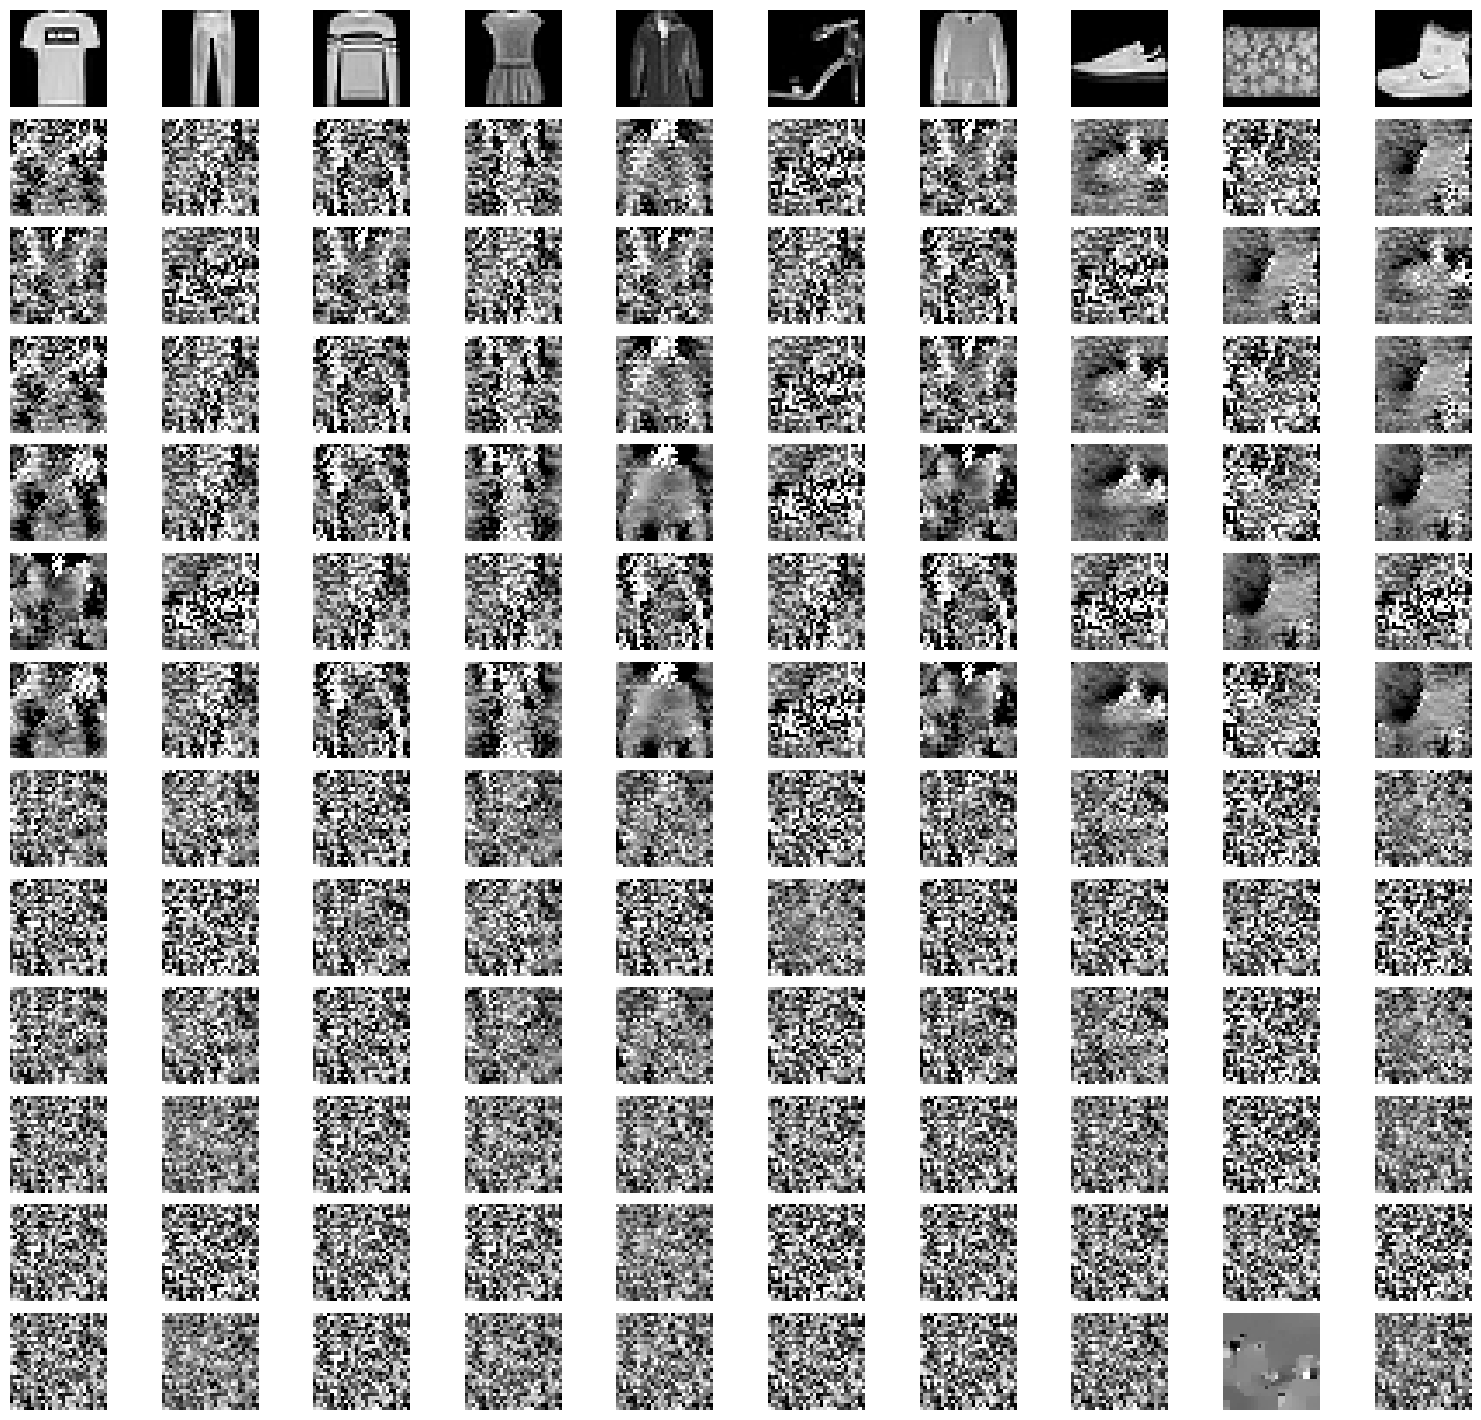

Saved: ./dlg_fmnist_4models/fmnist_all_attacks.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

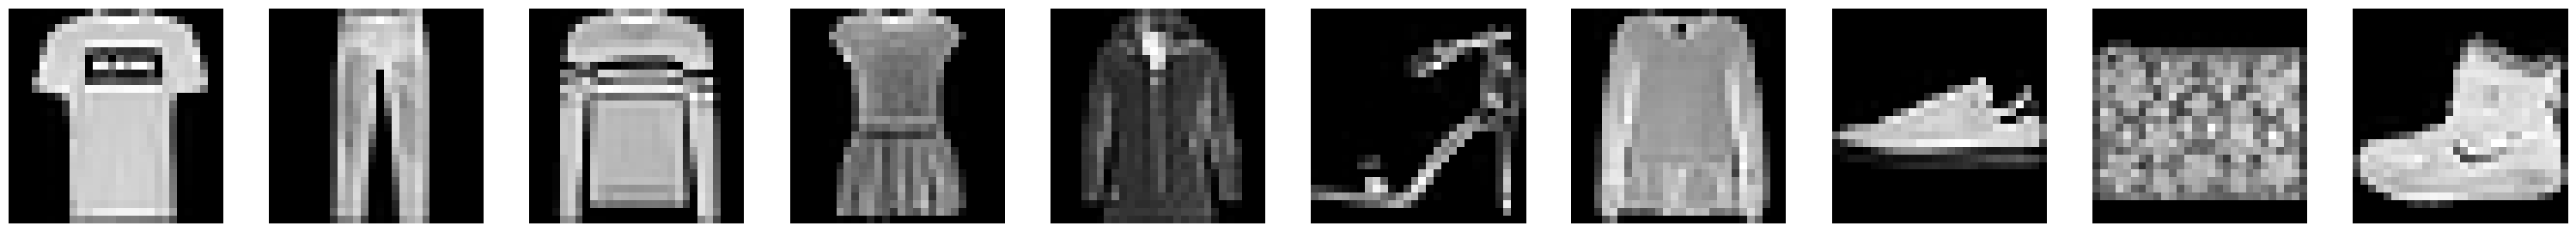

Saved: ./dlg_fmnist_4models/fmnist_original.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

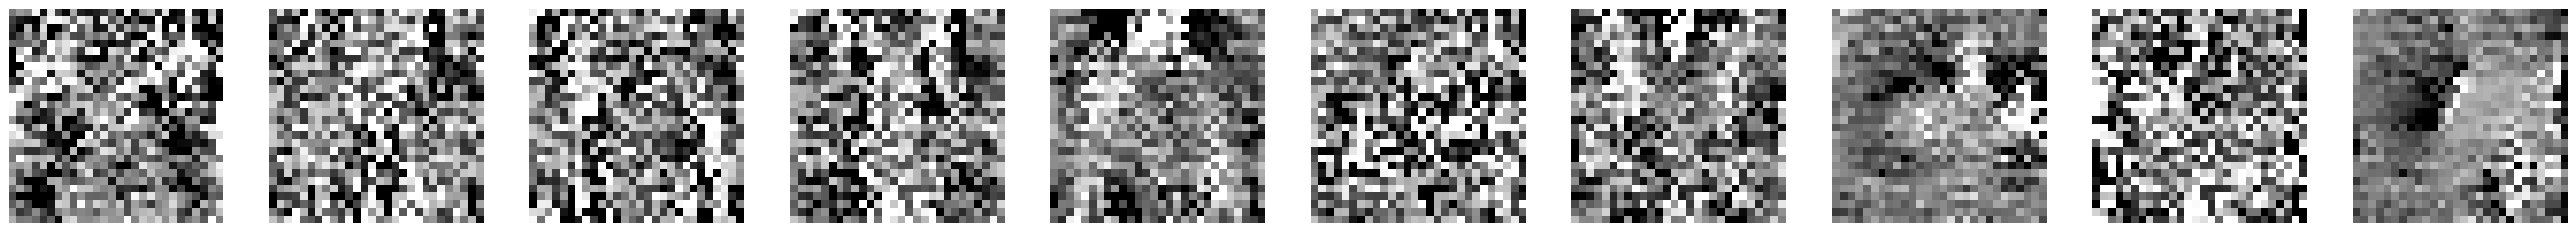

Saved: ./dlg_fmnist_4models/fmnist_baseline_dlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

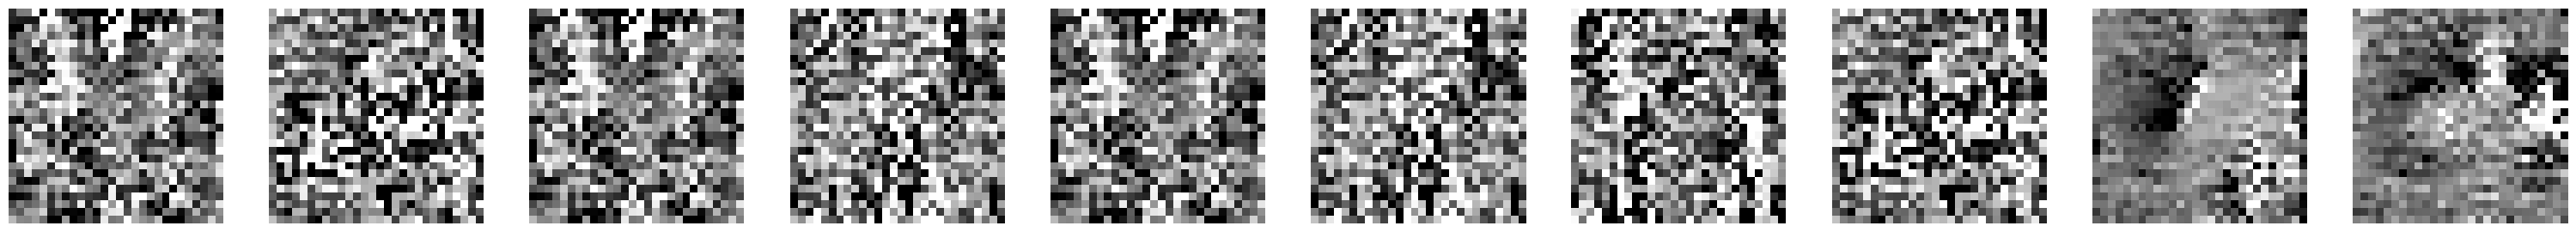

Saved: ./dlg_fmnist_4models/fmnist_baseline_idlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

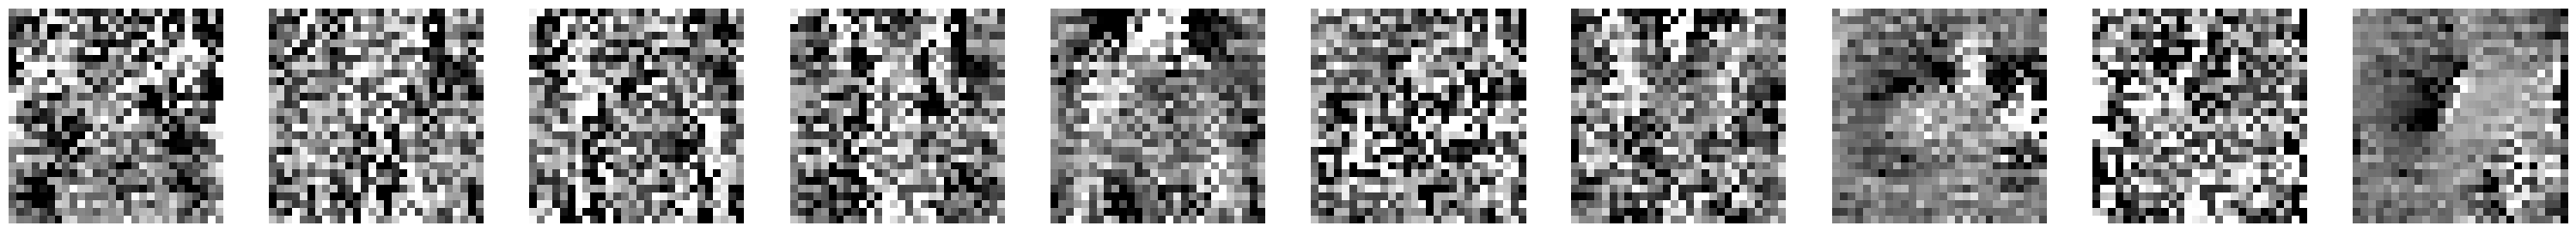

Saved: ./dlg_fmnist_4models/fmnist_baseline_gradinv.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

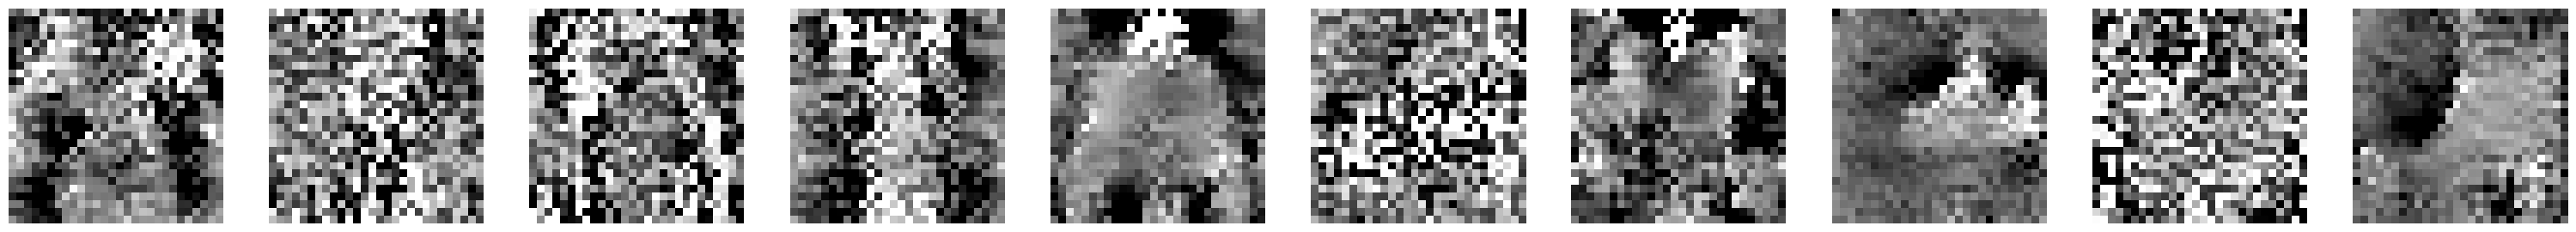

Saved: ./dlg_fmnist_4models/fmnist_fpman0_dlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

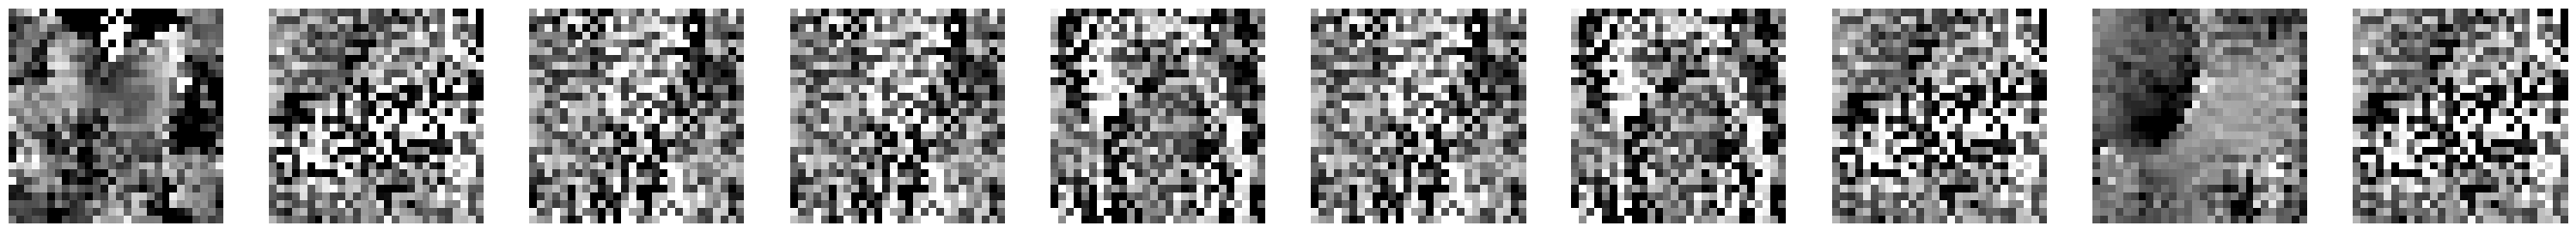

Saved: ./dlg_fmnist_4models/fmnist_fpman0_idlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

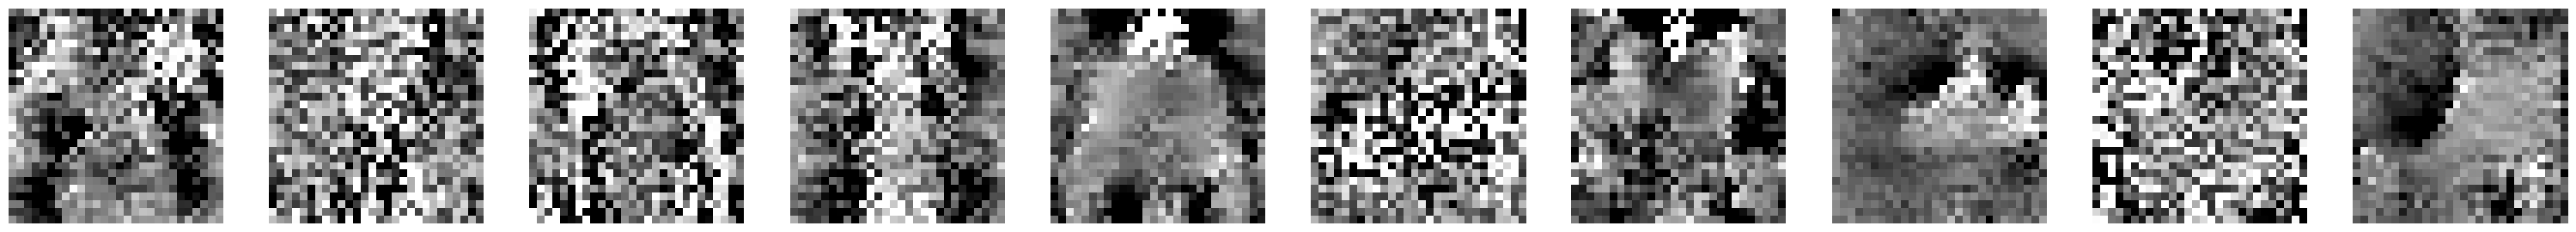

Saved: ./dlg_fmnist_4models/fmnist_fpman0_gradinv.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

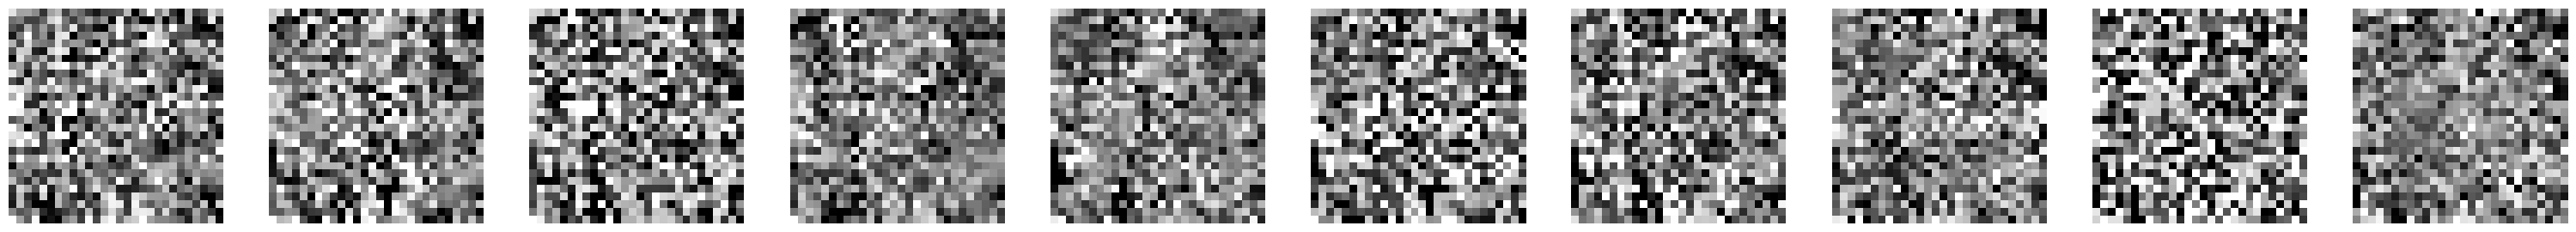

Saved: ./dlg_fmnist_4models/fmnist_fpman1_dlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

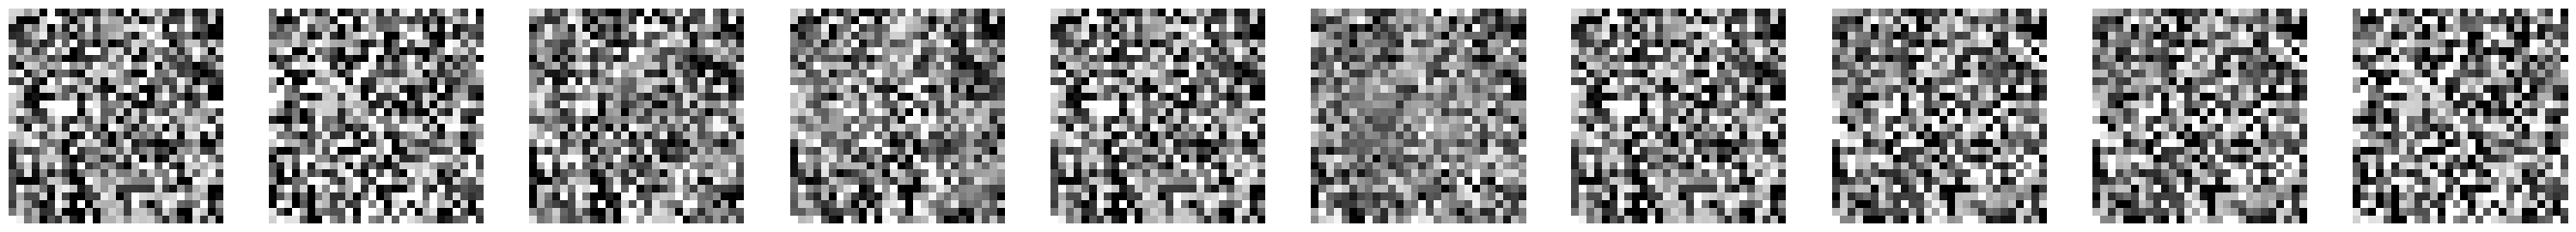

Saved: ./dlg_fmnist_4models/fmnist_fpman1_idlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

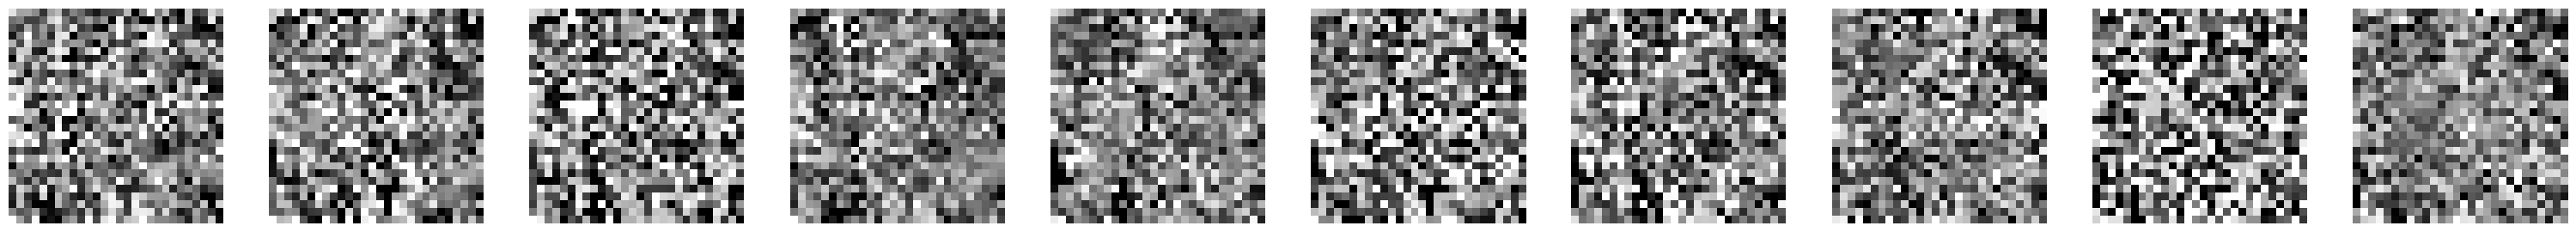

Saved: ./dlg_fmnist_4models/fmnist_fpman1_gradinv.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

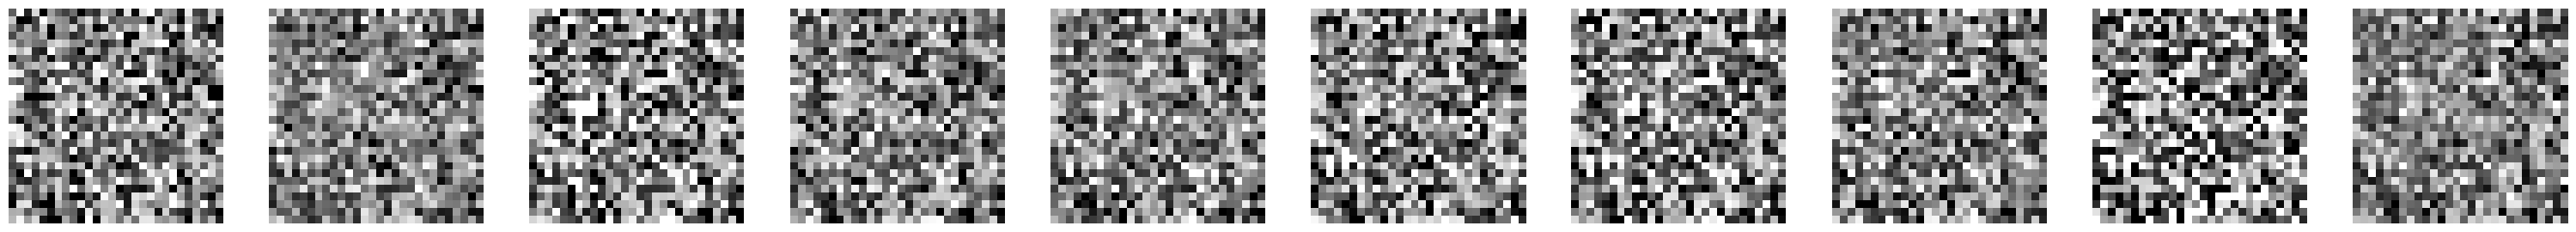

Saved: ./dlg_fmnist_4models/fmnist_fpman2_dlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

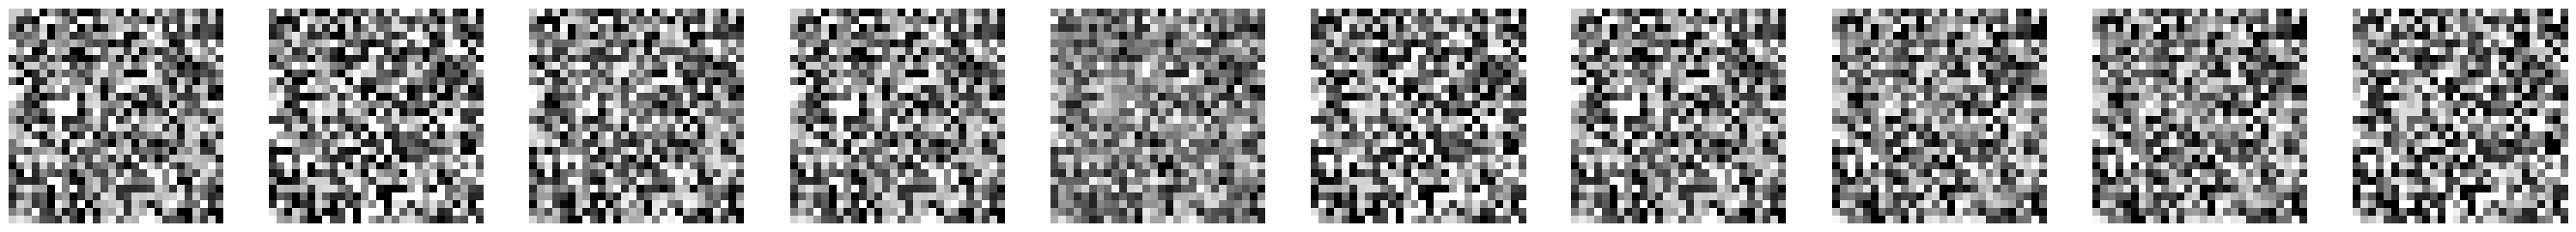

Saved: ./dlg_fmnist_4models/fmnist_fpman2_idlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

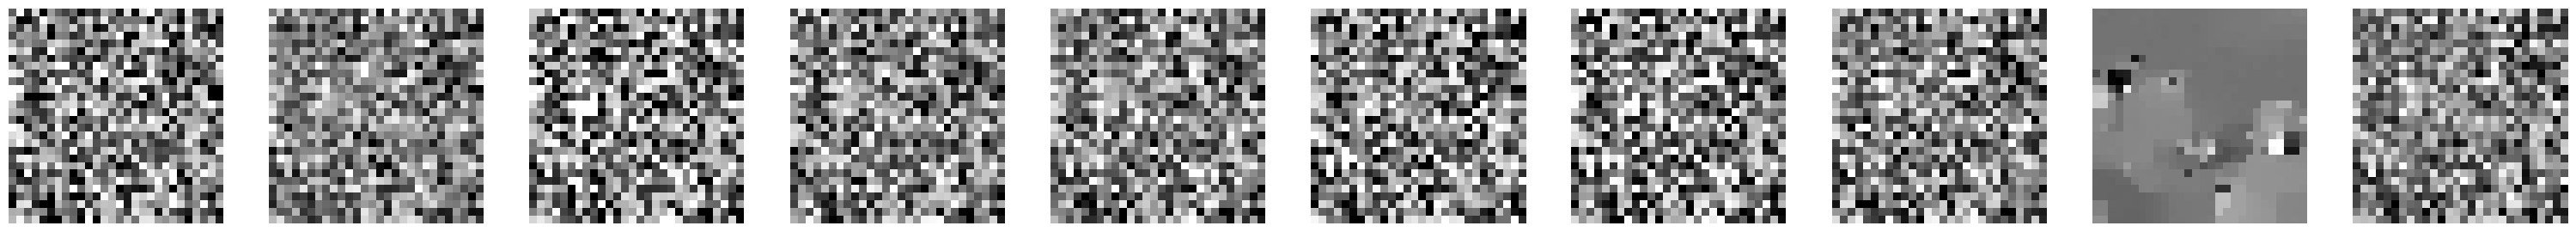

Saved: ./dlg_fmnist_4models/fmnist_fpman2_gradinv.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
import os
import matplotlib.pyplot as plt
from google.colab import files

SAVE_DIR = "./dlg_fmnist_4models"
os.makedirs(SAVE_DIR, exist_ok=True)

# -------------------------
# Data
# -------------------------
all_rows = [
    original,

    results["baseline"]["dlg"],
    results["baseline"]["idlg"],
    results["baseline"]["gi"],

    results["fpman0"]["dlg"],
    results["fpman0"]["idlg"],
    results["fpman0"]["gi"],

    results["fpman1"]["dlg"],
    results["fpman1"]["idlg"],
    results["fpman1"]["gi"],

    results["fpman2"]["dlg"],
    results["fpman2"]["idlg"],
    results["fpman2"]["gi"],
]

# =========================================================
# 1) FULL GRID (NO TOP/BOTTOM SPACE)
# =========================================================
fig, axes = plt.subplots(13, 10, figsize=(15, 14))

for r in range(13):
    for c in range(10):
        axes[r, c].imshow(all_rows[r][c], cmap="gray")
        axes[r, c].axis("off")

plt.subplots_adjust(
    wspace=0.12,
    hspace=0.12,          # ❌ no vertical gap
    left=0,
    right=1,
    top=1,
    bottom=0
)

full_path = os.path.join(SAVE_DIR, "fmnist_all_attacks.png")

plt.savefig(
    full_path,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0       # ❌ removes extra top/bottom margin
)

plt.show()

print("Saved:", full_path)
files.download(full_path)

# =========================================================
# 2) 13 SEPARATE ROW IMAGES (NO TOP/BOTTOM SPACE)
# =========================================================
row_names = [
    "fmnist_original",
    "fmnist_baseline_dlg",
    "fmnist_baseline_idlg",
    "fmnist_baseline_gradinv",
    "fmnist_fpman0_dlg",
    "fmnist_fpman0_idlg",
    "fmnist_fpman0_gradinv",
    "fmnist_fpman1_dlg",
    "fmnist_fpman1_idlg",
    "fmnist_fpman1_gradinv",
    "fmnist_fpman2_dlg",
    "fmnist_fpman2_idlg",
    "fmnist_fpman2_gradinv"
]

for i, row in enumerate(all_rows):

    fig, axes = plt.subplots(1, 10, figsize=(30, 2.5))

    for c in range(10):
        axes[c].imshow(row[c], cmap="gray")
        axes[c].axis("off")

    plt.subplots_adjust(
        wspace=0.12,
        hspace=0,
        left=0,
        right=1,
        top=1,
        bottom=0
    )

    path = os.path.join(SAVE_DIR, f"{row_names[i]}.png")

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight",
        pad_inches=0
    )

    plt.show()

    print("Saved:", path)
    files.download(path)